# Exploratory Data Analysis — Cybersecurity Incidents Dataset

This notebook performs EDA on a synthetic security-incident dataset (2,000 rows) and produces pie, bar, histogram, heatmap, choropleth, word cloud, dendrogram, scatter, pair plot, parallel coordinates, and Andrews curves visualizations.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from wordcloud import WordCloud
from scipy.cluster.hierarchy import dendrogram, linkage
from pandas.plotting import parallel_coordinates, andrews_curves

sns.set_theme(style="darkgrid")
plt.rcParams["figure.figsize"] = (10, 6)

## 1. Load the dataset

In [2]:
df = pd.read_csv("data/security_incidents.csv", parse_dates=["date"])
df.head()

,incident_id,date,attack_type,severity,country,protocol,source_port,dest_port,duration_sec,bytes_transferred,packets,risk_score,blocked,description
0,INC-00001,2025-11-05 01:00:00,Phishing,Critical,United States,HTTP,61287,3306,18.96,276658.27,691,95.18,False,Phishing incident via HTTP flagged as critical...
1,INC-00002,2025-07-07 15:00:00,DDoS,Medium,India,FTP,19966,443,1.00,5249.82,10,57.18,True,"DDoS incident via FTP flagged as medium risk, ..."
2,INC-00003,2025-04-02 14:00:00,Brute Force,Low,United States,HTTPS,24921,3389,114.03,82848.18,192,10.79,True,Brute Force incident via HTTPS flagged as low ...
3,INC-00004,2025-08-06 11:00:00,DDoS,Critical,India,HTTPS,41781,3389,67.24,330349.90,625,93.01,False,DDoS incident via HTTPS flagged as critical ri...
4,INC-00005,2025-06-06 14:00:00,Brute Force,Critical,China,UDP,40123,21,139.65,397667.41,510,89.07,True,Brute Force incident via UDP flagged as critic...


## 2. Dataset overview

In [3]:
print(df.shape)
print(df.dtypes)
df.isnull().sum()

(2000, 14)
incident_id                     str
date                 datetime64[us]
attack_type                     str
severity                        str
country                         str
protocol                        str
source_port                   int64
dest_port                     int64
duration_sec                float64
bytes_transferred           float64
packets                       int64
risk_score                  float64
blocked                        bool
description                     str
dtype: object


incident_id          0
date                 0
attack_type          0
severity             0
country              0
protocol             0
source_port          0
dest_port            0
duration_sec         0
bytes_transferred    0
packets              0
risk_score           0
blocked              0
description          0
dtype: int64

In [4]:
df.describe()

,date,source_port,dest_port,duration_sec,bytes_transferred,packets,risk_score
count,2000,2000.000000,2000.000000,2000.000000,2.000000e+03,2000.000000,2000.000000
mean,2025-06-30 13:50:25.800000,32961.170000,1894.099500,109.417450,2.894947e+05,667.369500,56.783790
min,2025-01-01 02:00:00,1029.000000,21.000000,1.000000,1.000000e+02,1.000000,1.000000
25%,2025-04-01 19:00:00,17018.250000,53.000000,25.175000,6.847804e+04,137.000000,38.720000
50%,2025-06-27 18:00:00,32516.000000,443.000000,66.635000,1.701712e+05,352.500000,57.035000
75%,2025-09-30 10:15:00,49069.000000,3306.000000,147.602500,3.871710e+05,835.250000,77.020000
max,2025-12-31 14:00:00,65449.000000,8080.000000,1442.760000,3.227055e+06,6973.000000,100.000000
std,NaN,18622.147794,2682.990521,129.060513,3.397412e+05,872.603769,25.302875


## 3. Pie chart — attack type share

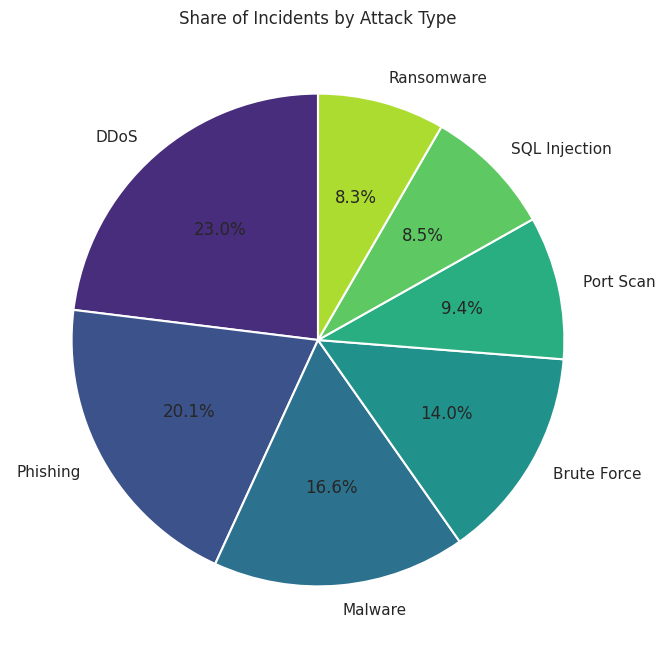

In [5]:
def plot_pie(data, labels, title="Pie Chart"):
    fig, ax = plt.subplots(figsize=(8, 8))
    colors = sns.color_palette("viridis", len(labels))
    ax.pie(data, labels=labels, autopct="%1.1f%%", startangle=90,
           colors=colors, wedgeprops={"edgecolor": "white", "linewidth": 1.5})
    ax.set_title(title)
    plt.show()

attack_counts = df["attack_type"].value_counts()
plot_pie(attack_counts.values, attack_counts.index.tolist(), title="Share of Incidents by Attack Type")

## 4. Bar chart — incidents by severity

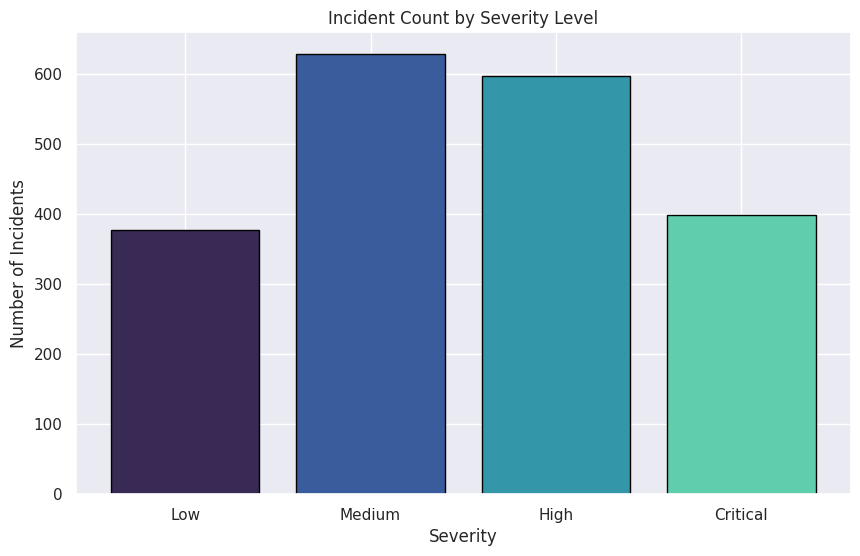

In [6]:
def plot_bar(categories, values, title="Bar Chart", xlabel="", ylabel="Count"):
    fig, ax = plt.subplots()
    colors = sns.color_palette("mako", len(categories))
    ax.bar(categories, values, color=colors, edgecolor="black")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    plt.show()

severity_counts = df["severity"].value_counts().reindex(["Low", "Medium", "High", "Critical"])
plot_bar(severity_counts.index.tolist(), severity_counts.values,
          title="Incident Count by Severity Level", xlabel="Severity", ylabel="Number of Incidents")

## 5. Histogram — risk score & duration

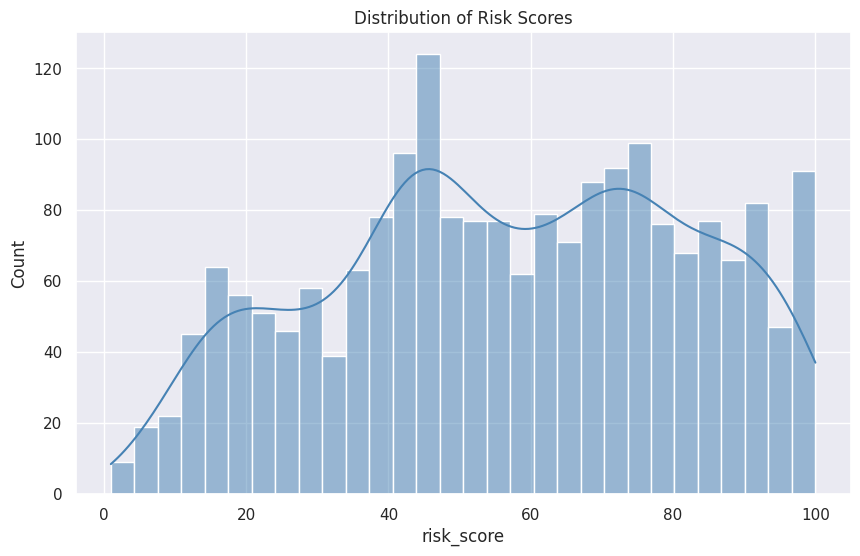

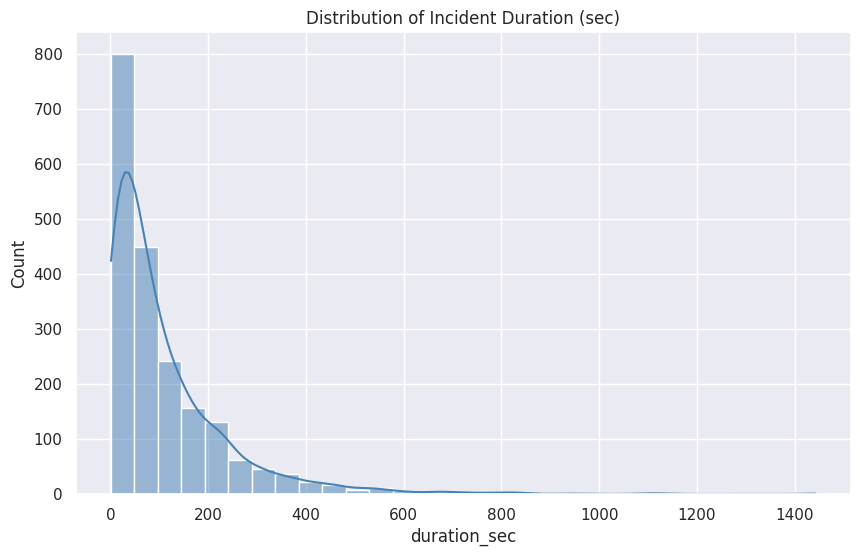

In [7]:
def plot_histogram(dataframe, column, title=None, bins=30):
    title = title or f"Distribution of {column}"
    fig, ax = plt.subplots()
    sns.histplot(dataframe[column], bins=bins, kde=True, color="steelblue", ax=ax)
    ax.set_title(title)
    plt.show()

plot_histogram(df, "risk_score", title="Distribution of Risk Scores")
plot_histogram(df, "duration_sec", title="Distribution of Incident Duration (sec)")

## 6. Correlation heat map

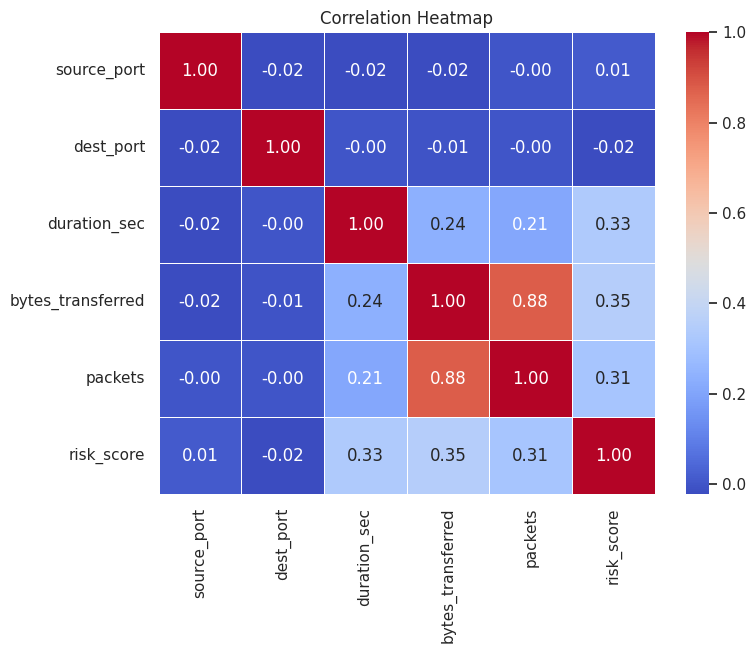

In [8]:
def heatmap(dataframe, annot=True, cmap="coolwarm", title="Correlation Heatmap"):
    numeric_df = dataframe.select_dtypes(include=[np.number])
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(numeric_df.corr(), annot=annot, cmap=cmap, fmt=".2f", linewidths=0.5, ax=ax)
    ax.set_title(title)
    plt.show()

heatmap(df, annot=True, cmap="coolwarm")

## 7. Choropleth map — incidents by country

In [9]:
country_counts = df.groupby("country").size().reset_index(name="incident_count")
fig = px.choropleth(
    country_counts,
    locations="country",
    locationmode="country names",
    color="incident_count",
    color_continuous_scale="Reds",
    title="Security Incidents by Country",
)
fig.show()

## 8. Word cloud — incident description tags

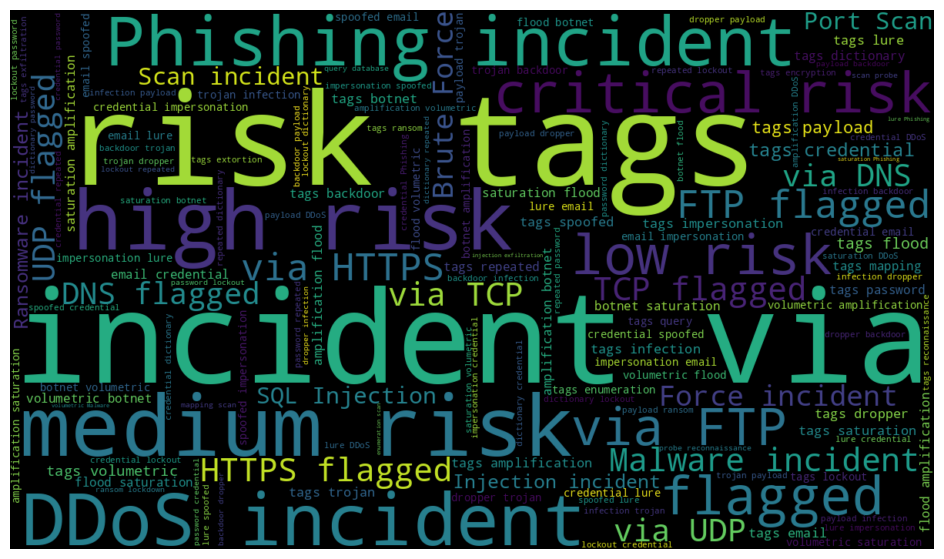

In [10]:
text = " ".join(df["description"].tolist())
wc = WordCloud(width=1200, height=700, background_color="black",
               colormap="viridis", max_words=150).generate(text)
fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(wc, interpolation="bilinear")
ax.axis("off")
plt.show()

## 9. Dendrogram — attack types by behavioral similarity

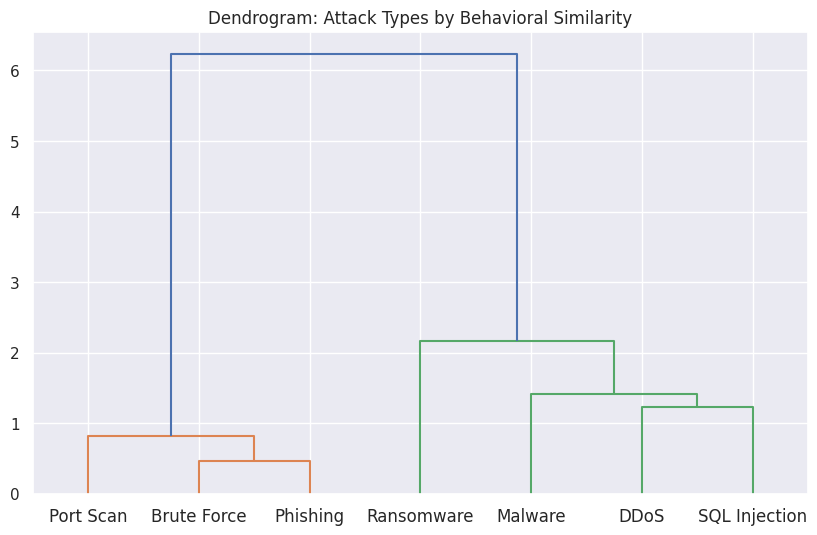

In [11]:
numeric_cols = ["duration_sec", "bytes_transferred", "packets", "risk_score"]
grouped = df.groupby("attack_type")[numeric_cols].mean()
scaled = (grouped - grouped.mean()) / grouped.std()
Z = linkage(scaled, method="ward")
fig, ax = plt.subplots(figsize=(10, 6))
dendrogram(Z, labels=grouped.index.tolist(), ax=ax, color_threshold=0.7 * max(Z[:, 2]))
ax.set_title("Dendrogram: Attack Types by Behavioral Similarity")
plt.show()

## 10. Scatter plot — duration vs. bytes transferred

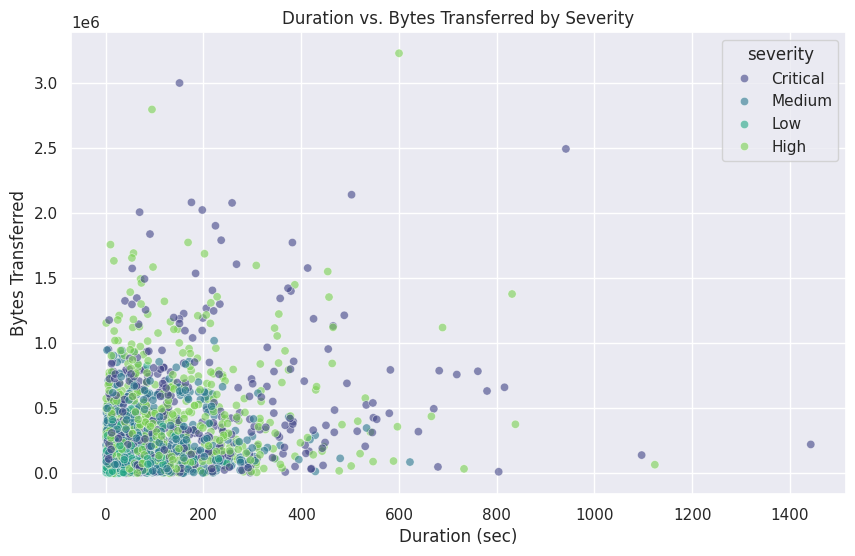

In [12]:
def scatter(x, y, title="Scatter Plot", xlabel="X", ylabel="Y", hue=None):
    fig, ax = plt.subplots()
    sns.scatterplot(x=x, y=y, hue=hue, palette="viridis", alpha=0.6, ax=ax)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    plt.show()

scatter(df["duration_sec"], df["bytes_transferred"],
        title="Duration vs. Bytes Transferred by Severity",
        xlabel="Duration (sec)", ylabel="Bytes Transferred", hue=df["severity"])

## 11. Pair plot

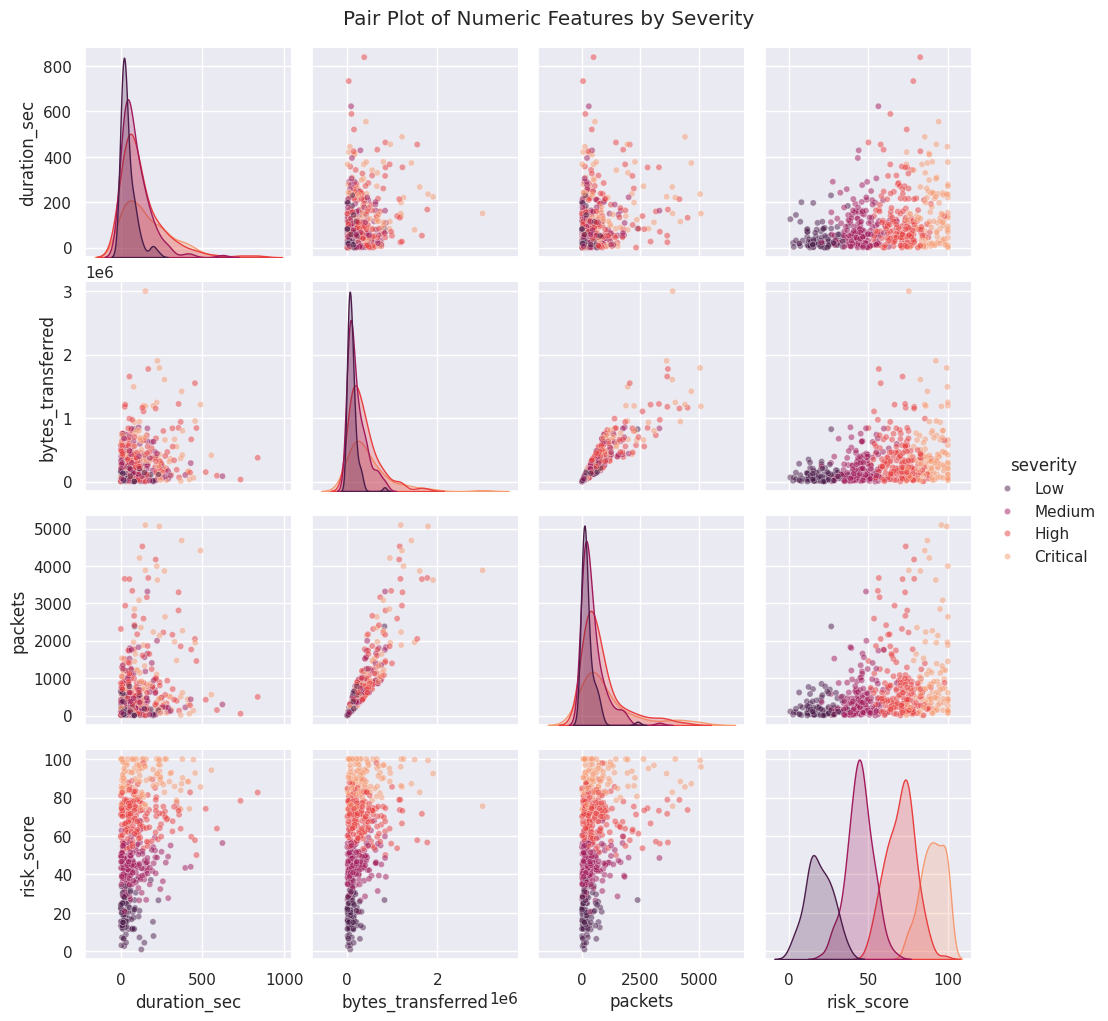

In [13]:
cols = ["duration_sec", "bytes_transferred", "packets", "risk_score", "severity"]
subset = df[cols].sample(min(500, len(df)), random_state=1)
g = sns.pairplot(subset, hue="severity", palette="rocket",
                  hue_order=["Low", "Medium", "High", "Critical"],
                  diag_kind="kde", plot_kws={"alpha": 0.5, "s": 20})
g.fig.suptitle("Pair Plot of Numeric Features by Severity", y=1.02)
plt.show()

## 12. Parallel coordinates

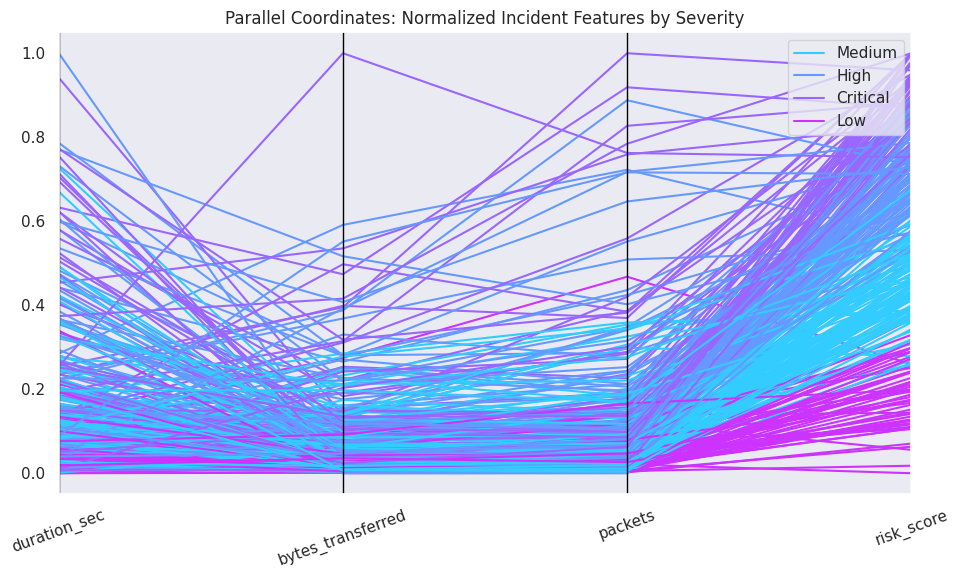

In [14]:
cols = ["duration_sec", "bytes_transferred", "packets", "risk_score", "severity"]
subset = df[cols].sample(min(300, len(df)), random_state=1).copy()
for c in ["duration_sec", "bytes_transferred", "packets", "risk_score"]:
    subset[c] = (subset[c] - subset[c].min()) / (subset[c].max() - subset[c].min())
fig, ax = plt.subplots(figsize=(11, 6))
parallel_coordinates(subset, "severity", color=sns.color_palette("cool", 4), ax=ax)
ax.set_title("Parallel Coordinates: Normalized Incident Features by Severity")
ax.tick_params(axis="x", rotation=20)
plt.show()

## 13. Andrews curves

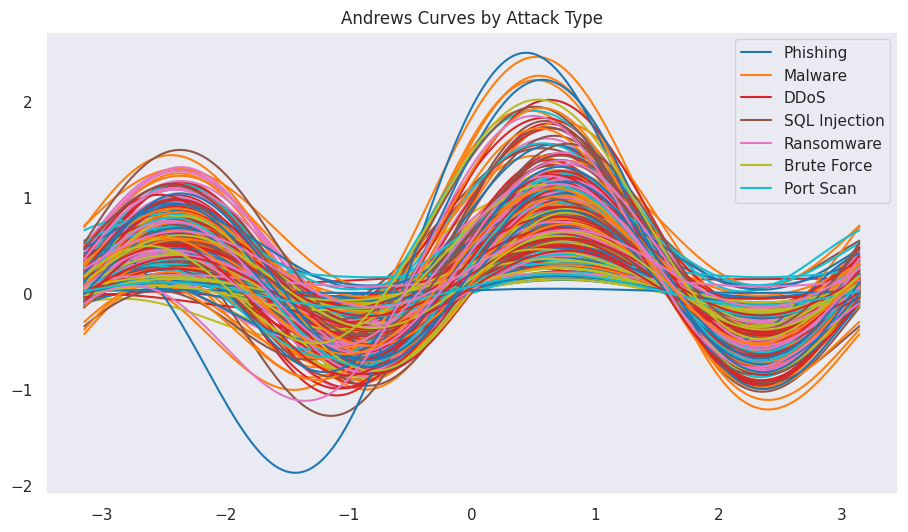

In [15]:
cols = ["duration_sec", "bytes_transferred", "packets", "risk_score", "attack_type"]
subset = df[cols].sample(min(300, len(df)), random_state=1).copy()
for c in ["duration_sec", "bytes_transferred", "packets", "risk_score"]:
    subset[c] = (subset[c] - subset[c].min()) / (subset[c].max() - subset[c].min())
fig, ax = plt.subplots(figsize=(11, 6))
andrews_curves(subset, "attack_type", ax=ax, colormap="tab10")
ax.set_title("Andrews Curves by Attack Type")
plt.show()

## 14. Key observations

- DDoS and Phishing together make up roughly 40% of incidents; Ransomware and SQL Injection are rarer but skew toward Critical severity.
- `risk_score` separates severity classes cleanly — visible in the histogram and the pair plot's diagonal density curves.
- High-severity incidents cluster at higher byte volumes but show no strong linear relationship with duration.
- The dendrogram groups DDoS and Malware as behaviorally similar (high volume, high packet count), while Port Scan and Brute Force form a separate low-intensity cluster.
- `bytes_transferred` and `packets` are strongly positively correlated; `duration_sec` correlates only weakly with the other numeric features.